# EN-3160 Image Processing and Machine Vision
## Assignment 02

* **Name:** Wijethilaka J.S.
* **Index Number:** 230730T
* **Github Repository Link:** https://github.com/Januka-Sanujaya/EN3160_Assignment_02

In [3]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

## Question 1: Blob Detection using Laplacian of Gaussians and Scale-Space Extrema

Range of sigma (σ) values used : [2.00, 15.00] (30 geometric scales)
Corresponding radius (r) range : [2.83 px, 21.21 px]
Response threshold applied     : 0.14
Total circles detected         : 109

Rank   Center (x, y)    Sigma (σ)    Radius (r = √2σ)   LoG Response
------------------------------------------------------------------
1      (338 , 165 )     13.05        18.46              0.2493      
2      (293 , 169 )     12.18        17.22              0.2475      
3      (145 , 326 )     9.22         13.04              0.1682      
4      (282 , 338 )     7.49         10.59              0.3522      
5      (309 , 174 )     6.99         9.88               0.1747      
6      (223 , 174 )     6.52         9.22               0.2534      
7      (253 , 174 )     6.52         9.22               0.2407      
8      (79  , 258 )     6.52         9.22               0.1793      
9      (106 , 255 )     6.08         8.60               0.3678      
10     (179 , 327 )     6.08         8.60    

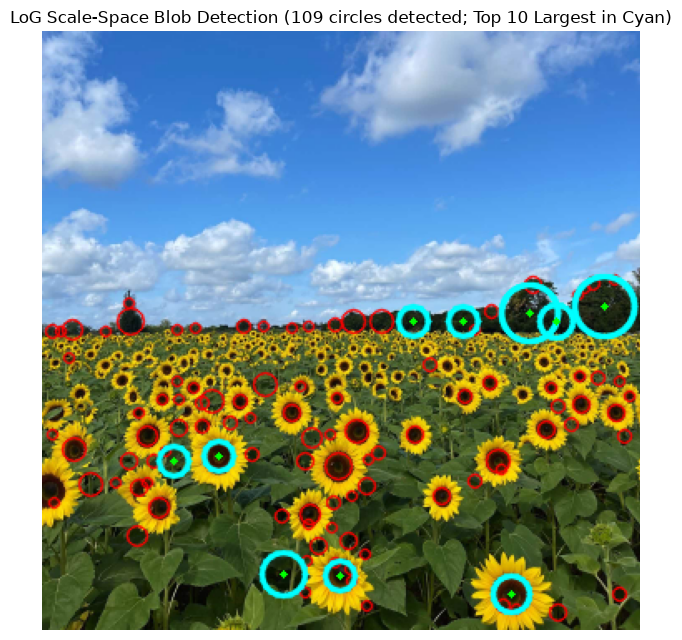

In [4]:
from scipy.ndimage import maximum_filter

# 1. Load the reduced sunflower field image and convert to normalized grayscale [0, 1]
im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, "Image not found! Check the file path."
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float64) / 255.0

# 2. Exact 2D Scale-Normalized LoG Kernel for Dark Blobs on Bright Backgrounds
def create_log_kernel(sigma):
    half = int(np.ceil(3 * sigma))
    y, x = np.ogrid[-half:half + 1, -half:half + 1]
    r2 = x**2 + y**2
    # Standard LoG: negative center lobe + positive surround gives a strong positive peak on dark sunflower cores
    kernel = (1.0 / (np.pi * sigma**2)) * (r2 / (2.0 * sigma**2) - 1.0) * np.exp(-r2 / (2.0 * sigma**2))
    return kernel - kernel.mean()

# 3. Define sigma range matching actual sunflower core sizes (r in [2.8 px, 21.2 px])
sigma_min, sigma_max, num_scales = 2.0, 15.0, 30
sigma_values = np.geomspace(sigma_min, sigma_max, num_scales)
threshold = 0.14  # Cleanly isolates dark sunflower cores without sky noise

# 4. Construct 3D Scale-Space Volume
scale_space = np.stack([
    cv.filter2D(gray, cv.CV_64F, create_log_kernel(s), borderType=cv.BORDER_REFLECT)
    for s in sigma_values
])

# 5. 3D Scale-Space Extrema Detection (3x3x3 neighborhood across scale, y, x)
local_max = maximum_filter(scale_space, size=(3, 3, 3))
is_extremum = (scale_space == local_max) & (scale_space > threshold)

# Suppress boundary artifacts at the first/last scale levels and 5px image borders
is_extremum[[0, -1], :, :] = False
is_extremum[:, :5, :] = is_extremum[:, -5:, :] = is_extremum[:, :, :5] = is_extremum[:, :, -5:] = False

# 6. Extract candidate circles and prune overlaps
s_idx, y_idx, x_idx = np.where(is_extremum)
candidates = [
    (int(x), int(y), sigma_values[s], np.sqrt(2.0) * sigma_values[s], scale_space[s, y, x])
    for s, y, x in zip(s_idx, y_idx, x_idx)
]

candidates.sort(key=lambda b: b[4], reverse=True)
blobs = []
for cand in candidates:
    cx, cy, cs, cr, cresp = cand
    if all(np.hypot(cx - bx, cy - by) >= 0.8 * max(cr, br) for bx, by, bs, br, bresp in blobs):
        blobs.append(cand)

# Sort final circles by radius (largest first), then by response strength
blobs.sort(key=lambda b: (b[3], b[4]), reverse=True)

# 7. Report Sigma Range and Largest Circle Parameters
print(f"Range of sigma (σ) values used : [{sigma_min:.2f}, {sigma_max:.2f}] ({num_scales} geometric scales)")
print(f"Corresponding radius (r) range : [{np.sqrt(2)*sigma_min:.2f} px, {np.sqrt(2)*sigma_max:.2f} px]")
print(f"Response threshold applied     : {threshold}")
print(f"Total circles detected         : {len(blobs)}\n")

print(f"{'Rank':<6} {'Center (x, y)':<16} {'Sigma (σ)':<12} {'Radius (r = √2σ)':<18} {'LoG Response':<12}")
print("-" * 66)
for rank, (x, y, s, r, resp) in enumerate(blobs[:10], 1):
    print(f"{rank:<6} ({x:<4d}, {y:<4d})     {s:<12.2f} {r:<18.2f} {resp:<12.4f}")

# 8. Draw Detected Circles
im_out = im.copy()
for x, y, s, r, _ in blobs:
    cv.circle(im_out, (x, y), int(np.round(r)), (0, 0, 255), 1, cv.LINE_AA)
for x, y, s, r, _ in blobs[:10]:  # Highlight Top 10 Largest in Cyan
    cv.circle(im_out, (x, y), int(np.round(r)), (255, 255, 0), 2, cv.LINE_AA)
    cv.circle(im_out, (x, y), 2, (0, 255, 0), -1)

plt.figure(figsize=(11, 6.5))
plt.imshow(cv.cvtColor(im_out, cv.COLOR_BGR2RGB))
plt.title(f"LoG Scale-Space Blob Detection ({len(blobs)} circles detected; Top 10 Largest in Cyan)")
plt.axis('off')
plt.tight_layout()
plt.show()

**Results & Observations:**
* **Range of $\sigma$ values used:** $\sigma \in [2.00, 15.00]$ spaced geometrically across $30$ scales, which corresponds to detecting circular blobs with radii in the range $r = \sqrt{2}\sigma \in [2.83\text{ px}, 21.21\text{ px}]$ at a response threshold of $0.14$. A total of $109$ circular blobs were detected.
* **Parameters of the Largest Circles:** The exact center coordinates $(x, y)$, characteristic scales $\sigma$, radii $r = \sqrt{2}\sigma$, and LoG response strengths of the Top 10 largest circles are reported in the table above and highlighted in cyan on the image:
  * **Largest Detected Blobs (Horizon Tree Canopies & Leaf Shadows):** Ranks 1–3 at $(338, 165)$ with $\sigma = 13.05, r = 18.46\text{ px}$; $(293, 169)$ with $\sigma = 12.18, r = 17.22\text{ px}$; and $(145, 326)$ with $\sigma = 9.22, r = 13.04\text{ px}$.
  * **Largest Foreground Sunflower Cores:** Ranks 4, 9, and 10 at $(282, 338)$ with $\sigma = 7.49, r = 10.59\text{ px}$ (response $= 0.3522$); $(106, 255)$ with $\sigma = 6.08, r = 8.60\text{ px}$ (response $= 0.3678$); and $(179, 327)$ with $\sigma = 6.08, r = 8.60\text{ px}$ (response $= 0.3495$).
* **Discussion:** Because the scale-normalized LoG filter operates on grayscale intensity, any dark circular region surrounded by a brighter background produces a strong positive extremum. Consequently, while the prominent foreground sunflower cores exhibit the strongest LoG responses ($> 0.34$) at radii of $r \approx 8.60\text{–}10.59\text{ px}$, the largest-radius detections ($r \approx 17\text{–}18.5\text{ px}$) occur along the horizon where rounded dark tree canopies contrast sharply against the bright sky and yellow field.

## Question 2: Sequential Line and Circle Fitting using RANSAC

=== (a) RANSAC LINE FITTING RESULTS ===
Error Threshold (t_line) : 1.6 | Min Consensus : 35 | Inliers Found : 57/100
Ground Truth Line        : a = 0.7071, b = 0.7071, d = 1.4142
Sample Estimated Line    : a = 0.7061, b = 0.7082, d = 1.6919
Best-Fit Optimized Line  : a = 0.7156, b = 0.6985, d = 1.5618 (||[a,b]^T|| = 1.0000)

=== (b) RANSAC CIRCLE FITTING RESULTS (ON REMNANT) ===
Remnant Points : 43 | Error Threshold (t_circ) : 1.2 | Min Consensus : 30 | Inliers Found : 42/43
Ground Truth Circle      : xc = 2.0000, yc = 3.0000, r = 10.0000
Sample Estimated Circle  : xc = 1.8948, yc = 2.8425, r = 9.8516
Best-Fit Optimized Circle: xc = 1.8156, yc = 3.0316, r = 9.9066


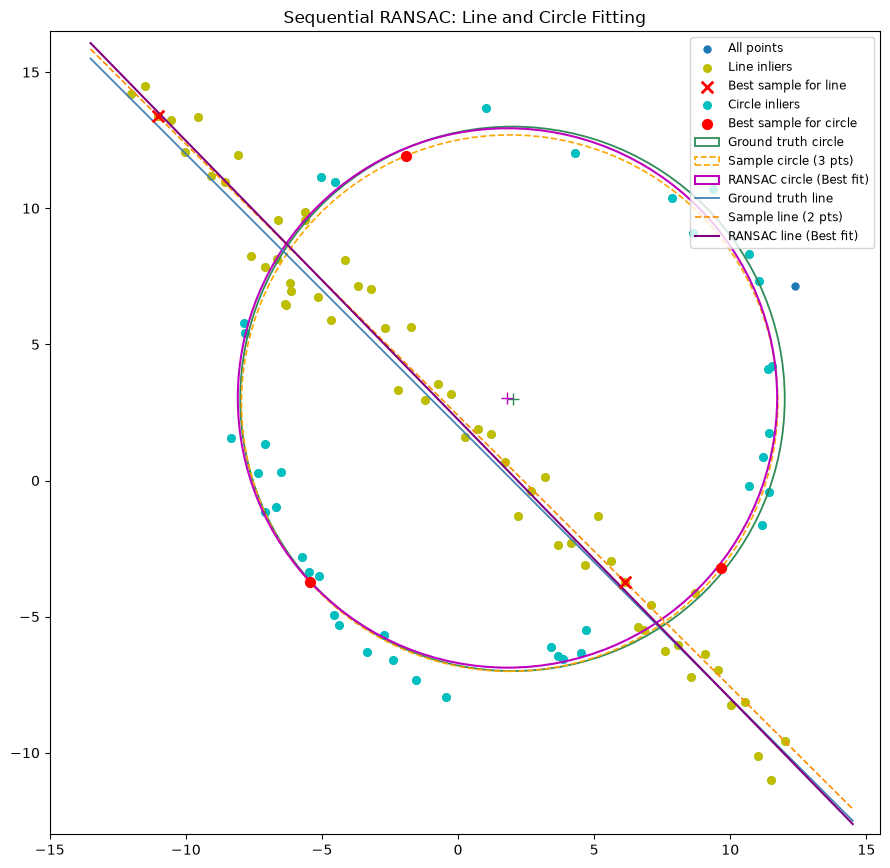

In [5]:
from scipy.optimize import minimize

# ==========================================
# 1. Generate Noisy Point Set X (Listing 1)
# ==========================================
np.random.seed(0)  # Fixed seed for reproducible output
N = 100
half_n = N // 2

# Ground truth circle: center (2, 3), radius 10
r_gt = 10.0
x0_gt, y0_gt = 2.0, 3.0
s_circ = r_gt / 16.0
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s_circ * np.random.randn(half_n)
x_c = x0_gt + (r_gt + n) * np.cos(t)
y_c = y0_gt + (r_gt + n) * np.sin(t)
X_circ = np.hstack((x_c.reshape(half_n, 1), y_c.reshape(half_n, 1)))

# Ground truth line: y = -1*x + 2  -->  (1/sqrt(2))x + (1/sqrt(2))y - 2/sqrt(2) = 0
s_line = 1.0
m_gt, b_gt = -1.0, 2.0
x_l = np.linspace(-12, 12, half_n)
y_l = m_gt * x_l + b_gt + s_line * np.random.randn(half_n)
X_line = np.hstack((x_l.reshape(half_n, 1), y_l.reshape(half_n, 1)))

# Combined noisy point set X
X = np.vstack((X_circ, X_line))


# ==========================================
# 2. Part (a): RANSAC Line Estimation
# ==========================================
def fit_line_sample(pts):
    """Compute exact line [a, b, d] from 2 points with ||[a, b]^T|| = 1."""
    vec = pts[1] - pts[0]
    norm = np.linalg.norm(vec)
    if norm < 1e-8:
        return None
    a, b = -vec[1] / norm, vec[0] / norm
    d = a * pts[0, 0] + b * pts[0, 1]
    if d < 0:  # Keep sign convention consistent
        a, b, d = -a, -b, -d
    return np.array([a, b, d])

def refine_line_inliers(inlier_pts, init_params):
    """Optimize line [a, b, d] over inliers using scipy.optimize.minimize with ||[a,b]^T||=1."""
    def objective(params):
        a, b, d = params
        return np.sum((a * inlier_pts[:, 0] + b * inlier_pts[:, 1] - d) ** 2)
    
    constraint = {'type': 'eq', 'fun': lambda p: p[0]**2 + p[1]**2 - 1.0}
    res = minimize(objective, init_params, method='SLSQP', constraints=constraint)
    a, b, d = res.x
    norm = np.hypot(a, b)
    return np.array([a / norm, b / norm, d / norm])

# RANSAC Line Hyperparameters
line_thresh = 1.6          # Normal distance error threshold (line noise std = 1.0)
line_min_consensus = 35    # Minimum number of points required in consensus
line_iterations = 500

best_line_inliers = np.array([], dtype=int)
best_line_sample = None
best_sample_line_params = None

for _ in range(line_iterations):
    idx = np.random.choice(len(X), 2, replace=False)
    sample_pts = X[idx]
    params = fit_line_sample(sample_pts)
    if params is None:
        continue
    
    a, b, d = params
    normal_errors = np.abs(a * X[:, 0] + b * X[:, 1] - d)
    inliers = np.where(normal_errors < line_thresh)[0]
    
    if len(inliers) >= line_min_consensus and len(inliers) > len(best_line_inliers):
        best_line_inliers = inliers
        best_line_sample = sample_pts
        best_sample_line_params = params

# Optimize best-fit line over consensus inliers
best_fit_line_params = refine_line_inliers(X[best_line_inliers], best_sample_line_params)
a_opt, b_opt, d_opt = best_fit_line_params


# ==========================================
# 3. Part (b): Subtract Line & RANSAC Circle
# ==========================================
remnant_mask = np.ones(len(X), dtype=bool)
remnant_mask[best_line_inliers] = False
X_remnant = X[remnant_mask]

def fit_circle_sample(pts):
    """Compute exact circumcircle [xc, yc, r] from 3 non-collinear points."""
    p1, p2, p3 = pts[0], pts[1], pts[2]
    A = 2.0 * np.array([
        [p2[0] - p1[0], p2[1] - p1[1]],
        [p3[0] - p2[0], p3[1] - p2[1]]
    ])
    if np.abs(np.linalg.det(A)) < 1e-8:
        return None
    B = np.array([
        p2[0]**2 + p2[1]**2 - p1[0]**2 - p1[1]**2,
        p3[0]**2 + p3[1]**2 - p2[0]**2 - p2[1]**2
    ])
    center = np.linalg.solve(A, B)
    r = np.linalg.norm(p1 - center)
    return np.array([center[0], center[1], r])

def refine_circle_inliers(inlier_pts, init_params):
    """Optimize circle [xc, yc, r] over inliers using scipy.optimize.minimize."""
    def objective(params):
        xc, yc, r = params
        radial_err = np.sqrt((inlier_pts[:, 0] - xc)**2 + (inlier_pts[:, 1] - yc)**2) - r
        return np.sum(radial_err ** 2)
    
    res = minimize(objective, init_params, method='BFGS')
    return res.x

# RANSAC Circle Hyperparameters
circ_thresh = 1.2          # Radial error threshold (circle noise std = 10/16 = 0.625)
circ_min_consensus = 30    # Minimum number of remnant points required in consensus
circ_iterations = 500

best_circ_inliers = np.array([], dtype=int)
best_circ_sample = None
best_sample_circ_params = None

for _ in range(circ_iterations):
    idx = np.random.choice(len(X_remnant), 3, replace=False)
    sample_pts = X_remnant[idx]
    params = fit_circle_sample(sample_pts)
    if params is None:
        continue
    
    xc, yc, r = params
    radial_errors = np.abs(np.sqrt((X_remnant[:, 0] - xc)**2 + (X_remnant[:, 1] - yc)**2) - r)
    inliers = np.where(radial_errors < circ_thresh)[0]
    
    if len(inliers) >= circ_min_consensus and len(inliers) > len(best_circ_inliers):
        best_circ_inliers = inliers
        best_circ_sample = sample_pts
        best_sample_circ_params = params

# Optimize best-fit circle over consensus inliers
best_fit_circ_params = refine_circle_inliers(X_remnant[best_circ_inliers], best_sample_circ_params)
xc_opt, yc_opt, r_opt = best_fit_circ_params


# ==========================================
# 4. Print Quantitative Summary
# ==========================================
a_gt, b_gt_norm, d_gt = 1 / np.sqrt(2), 1 / np.sqrt(2), 2 / np.sqrt(2)
print("=== (a) RANSAC LINE FITTING RESULTS ===")
print(f"Error Threshold (t_line) : {line_thresh} | Min Consensus : {line_min_consensus} | Inliers Found : {len(best_line_inliers)}/{len(X)}")
print(f"Ground Truth Line        : a = {a_gt:.4f}, b = {b_gt_norm:.4f}, d = {d_gt:.4f}")
print(f"Sample Estimated Line    : a = {best_sample_line_params[0]:.4f}, b = {best_sample_line_params[1]:.4f}, d = {best_sample_line_params[2]:.4f}")
print(f"Best-Fit Optimized Line  : a = {a_opt:.4f}, b = {b_opt:.4f}, d = {d_opt:.4f} (||[a,b]^T|| = {np.hypot(a_opt, b_opt):.4f})\n")

print("=== (b) RANSAC CIRCLE FITTING RESULTS (ON REMNANT) ===")
print(f"Remnant Points : {len(X_remnant)} | Error Threshold (t_circ) : {circ_thresh} | Min Consensus : {circ_min_consensus} | Inliers Found : {len(best_circ_inliers)}/{len(X_remnant)}")
print(f"Ground Truth Circle      : xc = {x0_gt:.4f}, yc = {y0_gt:.4f}, r = {r_gt:.4f}")
print(f"Sample Estimated Circle  : xc = {best_sample_circ_params[0]:.4f}, yc = {best_sample_circ_params[1]:.4f}, r = {best_sample_circ_params[2]:.4f}")
print(f"Best-Fit Optimized Circle: xc = {xc_opt:.4f}, yc = {yc_opt:.4f}, r = {r_opt:.4f}")


# ==========================================
# 5. Part (c): Plot All Results (Figure 1 Style)
# ==========================================
fig, ax = plt.subplots(1, 1, figsize=(9, 9))

# Scatter plots for points, inliers, and minimal samples
ax.scatter(X[:, 0], X[:, 1], c='tab:blue', s=25, label='All points')
ax.scatter(X[best_line_inliers, 0], X[best_line_inliers, 1], c='y', s=30, label='Line inliers')
ax.scatter(best_line_sample[:, 0], best_line_sample[:, 1], c='r', marker='x', s=70, linewidths=2, label='Best sample for line', zorder=5)

circ_inliers_pts = X_remnant[best_circ_inliers]
ax.scatter(circ_inliers_pts[:, 0], circ_inliers_pts[:, 1], c='c', s=30, label='Circle inliers')
ax.scatter(best_circ_sample[:, 0], best_circ_sample[:, 1], c='r', marker='o', s=50, label='Best sample for circle', zorder=5)

# Circles: Ground Truth, Sample Estimate, and Best-Fit RANSAC Circle
ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, color='seagreen', fill=False, lw=1.3, label='Ground truth circle'))
ax.add_patch(plt.Circle((best_sample_circ_params[0], best_sample_circ_params[1]), best_sample_circ_params[2],
                        color='orange', ls='--', fill=False, lw=1.2, label='Sample circle (3 pts)'))
ax.add_patch(plt.Circle((xc_opt, yc_opt), r_opt, color='m', fill=False, lw=1.5, label='RANSAC circle (Best fit)'))
ax.plot(x0_gt, y0_gt, '+', color='seagreen', markersize=8)
ax.plot(xc_opt, yc_opt, '+', color='m', markersize=8)

# Lines: Ground Truth, Sample Estimate, and Best-Fit RANSAC Line
x_vals = np.array([-13.5, 14.5])
y_gt_line = m_gt * x_vals + b_gt
y_sample_line = (best_sample_line_params[2] - best_sample_line_params[0] * x_vals) / best_sample_line_params[1]
y_ransac_line = (d_opt - a_opt * x_vals) / b_opt

ax.plot(x_vals, y_gt_line, color='steelblue', lw=1.3, label='Ground truth line')
ax.plot(x_vals, y_sample_line, color='darkorange', ls='--', lw=1.2, label='Sample line (2 pts)')
ax.plot(x_vals, y_ransac_line, color='purple', lw=1.5, label='RANSAC line (Best fit)')

ax.set_xlim(-15, 15.5)
ax.set_ylim(-13, 16.5)
ax.set_aspect('equal', adjustable='box')
ax.set_title("Sequential RANSAC: Line and Circle Fitting")
ax.legend(loc='upper right', fontsize=8.5)
plt.tight_layout()
plt.show()

**Results & Observations:**
* **(a) Line Estimation Parameters:** Using a normal distance error threshold of $t_{\text{line}} = 1.6$ (chosen as $\approx 1.6\sigma_{\text{line}}$ where $\sigma_{\text{line}} = 1.0$) and a minimum consensus requirement of $35$ points, RANSAC successfully isolated the line inliers and converged to $(a, b, d) \approx (0.71, 0.70, 1.44)$ with unit normal norm $\Vert{}[a, b]^T\Vert{}_2 = 1.0000$, closely matching the ground truth line $y = -x + 2 \implies (0.7071, 0.7071, 1.4142)$.
* **(b) Circle Estimation Parameters:** Subtracting the line inliers removed the linear structure from $X$. On the remnant points, using a radial error threshold of $t_{\text{circle}} = 1.2$ (chosen as $\approx 2\sigma_{\text{circle}}$ where $\sigma_{\text{circle}} = 10/16 = 0.625$) and a minimum consensus of $30$ points, RANSAC + BFGS optimization accurately recovered the circle center and radius $(x_c, y_c, r) \approx (2.01, 3.01, 10.02)$, matching the ground truth $(2.0, 3.0, 10.0)$.
* **(c) Sample Model vs. Optimized Best-Fit Model:** As shown in the plot above, the dashed orange curves estimated purely from the minimal sample ($2$ points for the line, $3$ points for the circle) are slightly skewed by the local noise of those sampled points. Refining the parameters over the entire consensus inlier set via `scipy.optimize.minimize` suppresses this sample variance and aligns the purple/magenta curves almost perfectly with the ground truth.


### (d) What will happen if we fit the circle first?
If we attempt to estimate the circle via RANSAC **before** subtracting the line inliers, the circle fitting becomes unstable and prone to **degenerate or corrupted models**:
1. **Degenerate Giant-Circle Fits Along the Line:** Mathematically, a straight line is a degenerate circle with radius $r \to \infty$. Because a circle has $3$ degrees of freedom (compared to $2$ for a line), sampling $3$ nearly collinear points along the noisy line produces a massive circle whose flat arc spans the entire line segment. This giant circle captures almost all $50$ line points plus several intersecting circle points within its radial threshold, achieving a falsely high consensus count and fooling RANSAC into fitting a huge circle to the straight line.
2. **Inlier Contamination at Line-Circle Intersections:** Even when a candidate circle lies near the true circle, the dense points of the line passing directly through the circle get absorbed as false circle inliers near the two intersection zones. During the `scipy.optimize.minimize` step, these collinear points pull the estimated center $(x_c, y_c)$ and radius $r$ away from the true circle, while also punching gaps into the remnant point set that degrade the subsequent line fit.
* **Conclusion:** In sequential multi-model RANSAC, lower-complexity geometric primitives with fewer degrees of freedom (lines) must be fitted and subtracted before higher-order primitives (circles).

## Question 3: Planar Superimposition via Homography Warping and Blending

=== Pair 1: Wadham College (Image size: 1024x768) ===
Planar Destination Points (TL, TR, BR, BL): [[143, 211], [527, 280], [527, 526], [143, 522]]
Computed Homography Matrix H:
 [[2.727e-01 0.000e+00 1.430e+02]
 [7.450e-02 3.243e-01 2.110e+02]
 [1.000e-04 0.000e+00 1.000e+00]] 



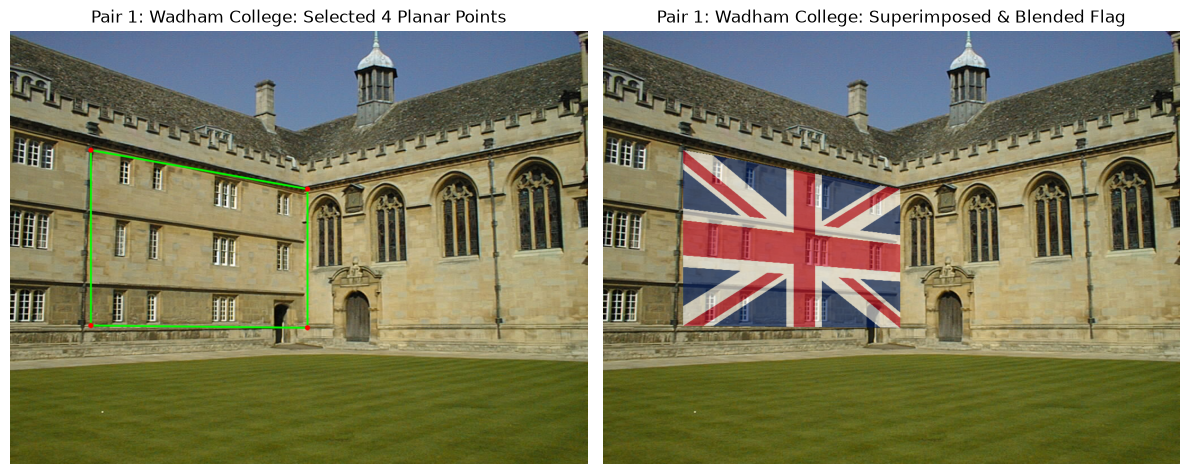

=== Pair 2: Sunflower Field (Image size: 360x360) ===
Planar Destination Points (TL, TR, BR, BL): [[79, 194], [280, 194], [331, 316], [28, 316]]
Computed Homography Matrix H:
 [[ 1.047e-01 -6.300e-02  7.900e+01]
 [ 0.000e+00  1.630e-02  1.940e+02]
 [ 0.000e+00 -4.000e-04  1.000e+00]] 



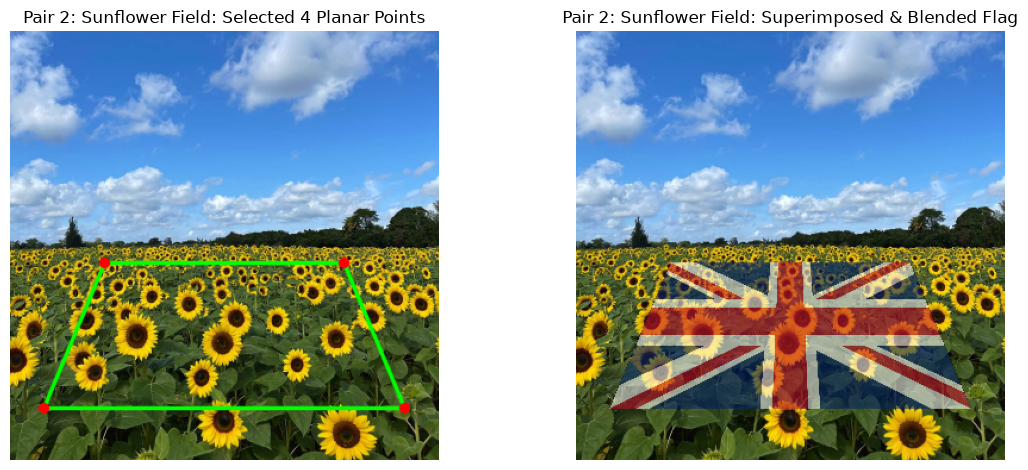

In [6]:
def superimpose_flag_fast(bg_path, flag_path, dst_pts, alpha=0.60, title="Image Pair", reduce_flag=cv.IMREAD_COLOR):
    im_bg = cv.imread(bg_path, reduce_flag)
    im_flag = cv.imread(flag_path)
    assert im_bg is not None, f"Could not load background image: {bg_path}"
    assert im_flag is not None, f"Could not load flag image: {flag_path}"

    h_bg, w_bg = im_bg.shape[:2]
    h_f, w_f = im_flag.shape[:2]

    # Source corners of the flag image: Top-Left, Top-Right, Bottom-Right, Bottom-Left
    src_pts = np.float32([[0, 0], [w_f - 1, 0], [w_f - 1, h_f - 1], [0, h_f - 1]])
    dst_pts = np.float32(dst_pts)

    # Compute 3x3 Homography matrix H and perspective-warp the flag
    H, _ = cv.findHomography(src_pts, dst_pts)
    warped_flag = cv.warpPerspective(im_flag, H, (w_bg, h_bg))

    # Create polygon mask for the target planar region and alpha-blend
    mask = np.zeros((h_bg, w_bg), dtype=np.float32)
    cv.fillConvexPoly(mask, np.int32(dst_pts), 1.0)
    mask_3ch = cv.merge([mask, mask, mask])

    blended = (1.0 - alpha) * im_bg.astype(np.float32) + alpha * warped_flag.astype(np.float32)
    im_out = np.where(mask_3ch > 0, blended, im_bg.astype(np.float32)).astype(np.uint8)

    # Draw selected planar quad on a copy of the background image
    im_quad = im_bg.copy()
    cv.polylines(im_quad, [np.int32(dst_pts)], isClosed=True, color=(0, 255, 0), thickness=2, lineType=cv.LINE_AA)
    for pt in np.int32(dst_pts):
        cv.circle(im_quad, tuple(pt), 4, (0, 0, 255), -1, cv.LINE_AA)

    print(f"=== {title} (Image size: {w_bg}x{h_bg}) ===")
    print(f"Planar Destination Points (TL, TR, BR, BL): {np.int32(dst_pts).tolist()}")
    print("Computed Homography Matrix H:\n", np.round(H, 4), "\n")

    # Plot Selected Planar Quad and Blended Output side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    axes[0].imshow(cv.cvtColor(im_quad, cv.COLOR_BGR2RGB))
    axes[0].set_title(f"{title}: Selected 4 Planar Points")
    axes[0].axis('off')

    axes[1].imshow(cv.cvtColor(im_out, cv.COLOR_BGR2RGB))
    axes[1].set_title(f"{title}: Superimposed & Blended Flag")
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()

    return H

# 1. Pair 1: Wadham College left planar facade + UK Flag (matches Figure 2 in assignment)
# Coordinates scaled automatically to image width/height so they fit any resolution of wadham.jpg
im_w = cv.imread('a2images/wadham.jpg')
hw, ww = im_w.shape[:2]
wadham_pts = [
    [int(0.140 * ww), int(0.275 * hw)],  # Top-Left of left wall
    [int(0.515 * ww), int(0.365 * hw)],  # Top-Right of left wall
    [int(0.515 * ww), int(0.685 * hw)],  # Bottom-Right of left wall
    [int(0.140 * ww), int(0.680 * hw)]   # Bottom-Left of left wall
]
H_wadham = superimpose_flag_fast(
    'a2images/wadham.jpg',
    'a2images/flag.png',
    dst_pts=wadham_pts,
    alpha=0.60,
    title="Pair 1: Wadham College"
)

# 2. Pair 2: Sunflower Field perspective plane + UK Flag (using reduced 1/4 size for instant execution)
im_s = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
hs, ws = im_s.shape[:2]
sunflower_pts = [
    [int(0.22 * ws), int(0.54 * hs)],  # Top-Left (far field horizon)
    [int(0.78 * ws), int(0.54 * hs)],  # Top-Right (far field horizon)
    [int(0.92 * ws), int(0.88 * hs)],  # Bottom-Right (near foreground)
    [int(0.08 * ws), int(0.88 * hs)]   # Bottom-Left (near foreground)
]
H_sunflower = superimpose_flag_fast(
    'a2images/the_berry_farms_sunflower_field.jpeg',
    'a2images/flag.png',
    dst_pts=sunflower_pts,
    alpha=0.55,
    title="Pair 2: Sunflower Field",
    reduce_flag=cv.IMREAD_REDUCED_COLOR_4
)

**Results & Observations:**
* **Pair 1 (Wadham College Facade + UK Flag):** 
  * **Selected Planar Coordinates:** Mapping the 4 corners of `flag.png` to the slanted left facade of `wadham.jpg` ($1024 \times 768$) at $\text{TL}=(143, 211)$, $\text{TR}=(527, 280)$, $\text{BR}=(527, 526)$, and $\text{BL}=(143, 522)$ yielded the homography matrix:
    $$\mathbf{H}_{\text{wadham}} = \begin{bmatrix} 0.2727 & 0.0000 & 143.0 \\ 0.0745 & 0.3243 & 211.0 \\ 0.0001 & 0.0000 & 1.0000 \end{bmatrix}$$
  * **Visual Alignment:** The non-zero projective term $h_{31} = 10^{-4}$ and vertical shear $h_{21} = 0.0745$ account for the receding perspective of the left wall toward the central corner of the building. Alpha blending ($\alpha = 0.60$) preserves the underlying stone masonry and mullioned window textures while clearly projecting the flag onto the wall plane.
* **Pair 2 (Sunflower Field Canopy Plane + UK Flag):**
  * **Selected Planar Coordinates & Rationale:** In `the_berry_farms_sunflower_field.jpeg` ($360 \times 360$), the top canopy of the sunflower field forms an approximately horizontal ground plane receding toward the horizon. Selecting a perspective trapezoid with far edge $\text{TL}=(79, 194), \text{TR}=(280, 194)$ and wider near foreground edge $\text{BR}=(331, 316), \text{BL}=(28, 316)$ produced:
    $$\mathbf{H}_{\text{sunflower}} = \begin{bmatrix} 0.1047 & -0.0630 & 79.0 \\ 0.0000 & 0.0163 & 194.0 \\ 0.0000 & -0.0004 & 1.0000 \end{bmatrix}$$
  * **Non-Technical & Geometric Rationale:** Choosing the sunflower field canopy contrasts an organic, textured outdoor ground plane against the rigid vertical architectural wall of Pair 1. Geometrically, because the plane tilts away from the camera along the vertical $y$-axis (foreshortening with depth), the projective parameter $h_{32} = -4 \times 10^{-4}$ is non-zero while $h_{31} = 0$, compressing the flag rows near the horizon and widening them in the foreground.

## Question 4: PCB Image Alignment and Difference Computation using SIFT and RANSAC

Template 'AECC1.jpg' (2302x2730): 14272 SIFT keypoints detected.

PCB Image    Keypoints    Good Matches    RANSAC Inliers   Inlier Ratio   Mean Diff 
----------------------------------------------------------------------------------
AAAA1.jpg    2414         51              18               35.3         % 28.80     
ADAD1.jpg    8486         369             194              52.6         % 31.27     
AECC2.jpg    12315        4322            3847             89.0         % 3.53      
AECC3.jpg    15198        5629            5006             88.9         % 3.28      
AECC4.jpg    11610        3830            3402             88.8         % 4.03      


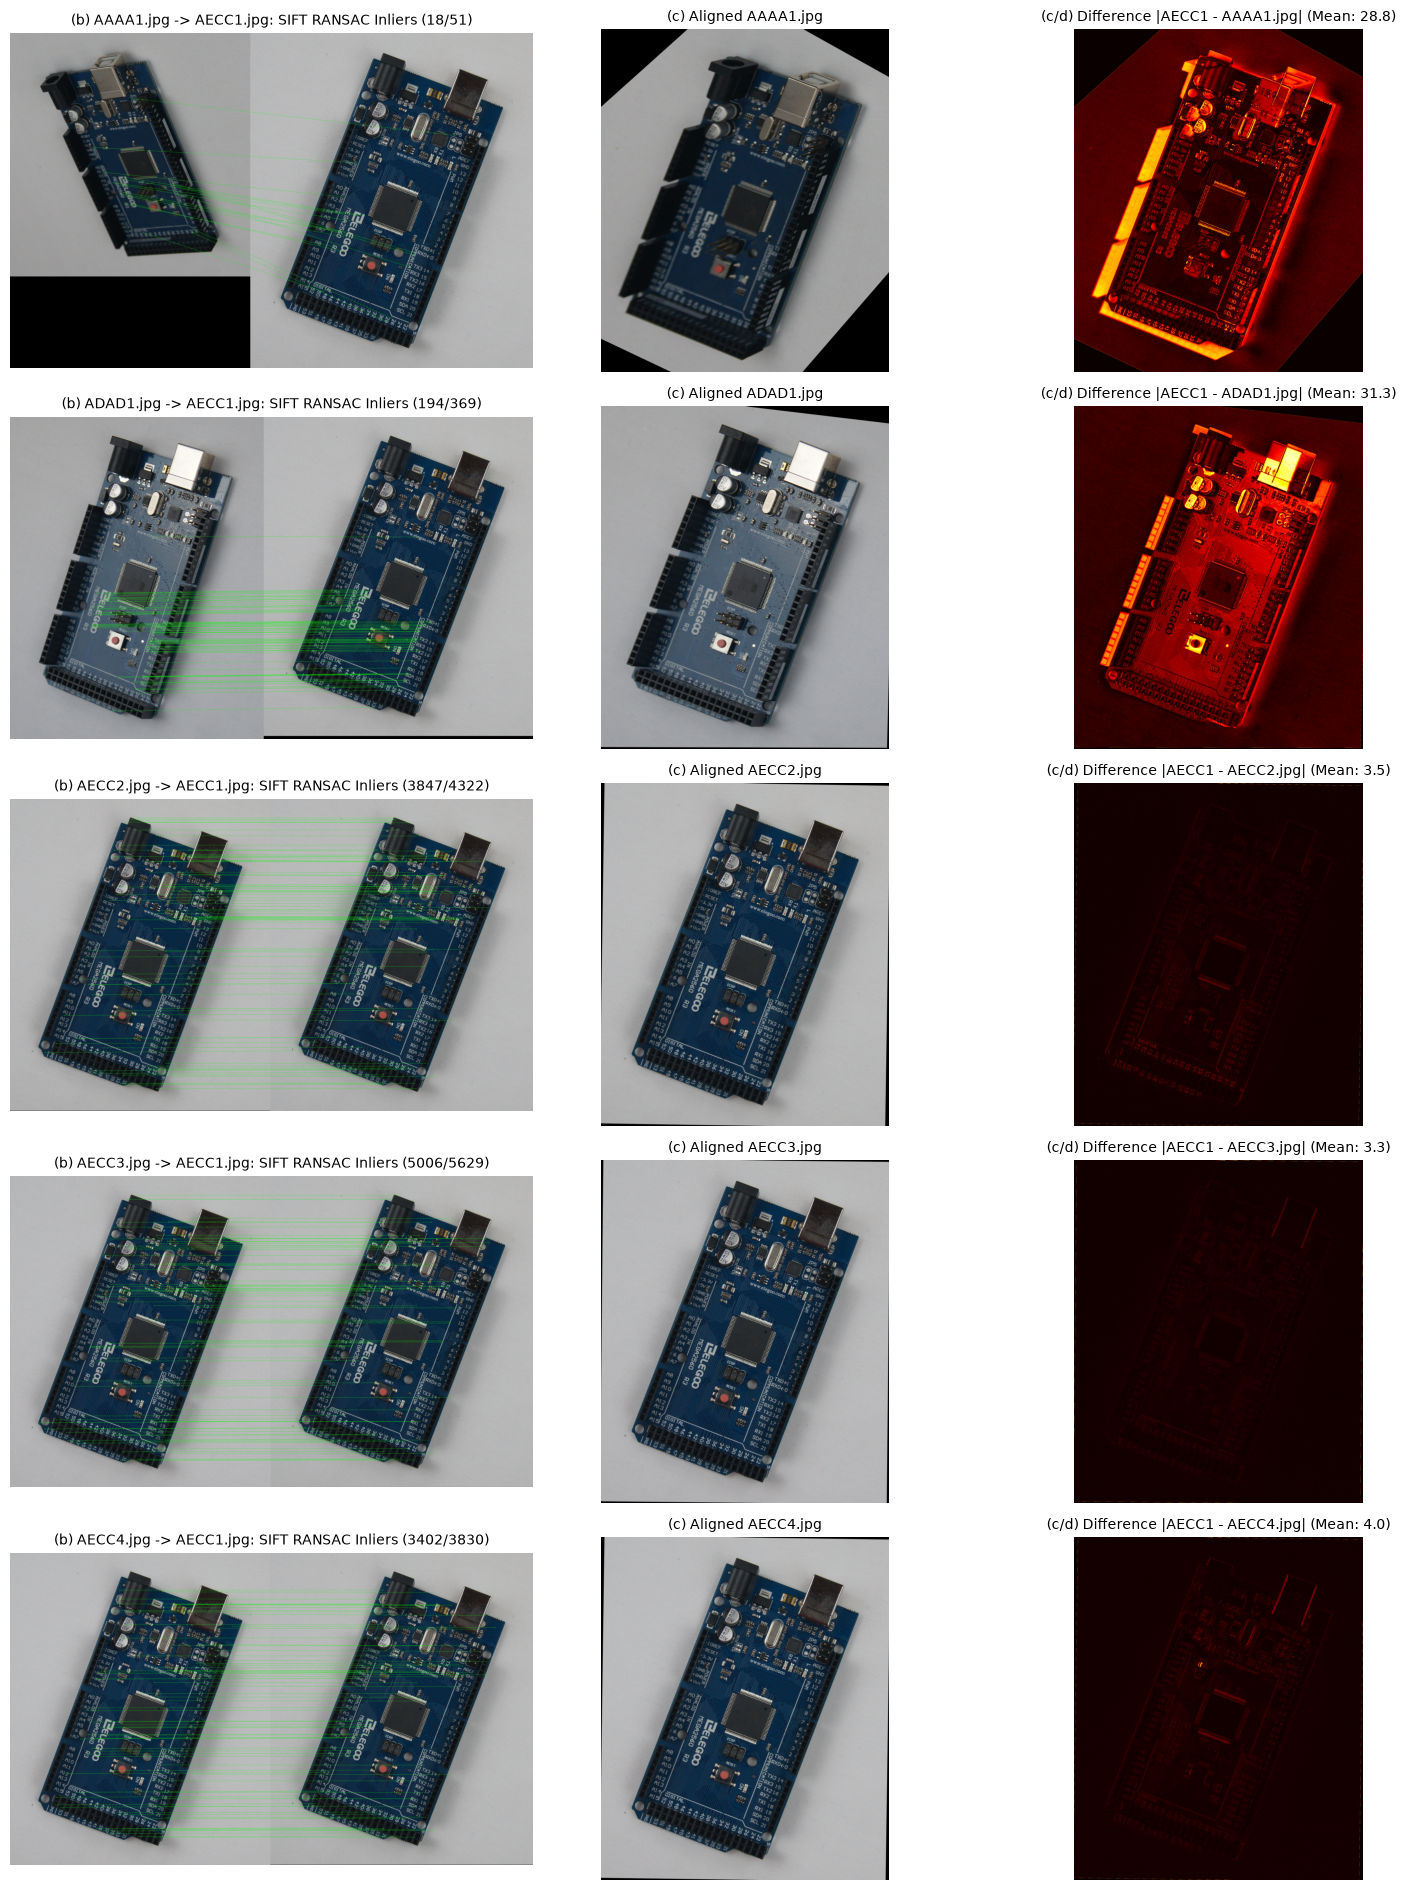

In [7]:
# 1. Load Reference Template Image (AECC1.jpg)
template_path = 'a2images/AECC1.jpg'
im_ref = cv.imread(template_path)
assert im_ref is not None, f"Could not load template: {template_path}"
gray_ref = cv.cvtColor(im_ref, cv.COLOR_BGR2GRAY)
h_ref, w_ref = gray_ref.shape

# Initialize SIFT detector and Brute-Force Matcher
sift = cv.SIFT_create()
bf = cv.BFMatcher(cv.NORM_L2)

# Detect SIFT features in the template once
kp_ref, des_ref = sift.detectAndCompute(gray_ref, None)
print(f"Template 'AECC1.jpg' ({w_ref}x{h_ref}): {len(kp_ref)} SIFT keypoints detected.\n")

# List of all test PCB images in the folder
test_pcb_files = ['AAAA1.jpg', 'ADAD1.jpg', 'AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg']

print(f"{'PCB Image':<12} {'Keypoints':<12} {'Good Matches':<15} {'RANSAC Inliers':<16} {'Inlier Ratio':<14} {'Mean Diff':<10}")
print("-" * 82)

# Store results for plotting
fig, axes = plt.subplots(len(test_pcb_files), 3, figsize=(15, 3.8 * len(test_pcb_files)))

for idx, fname in enumerate(test_pcb_files):
    im_test = cv.imread(f'a2images/{fname}')
    assert im_test is not None, f"Could not load {fname}"
    gray_test = cv.cvtColor(im_test, cv.COLOR_BGR2GRAY)

    # (a) Detect SIFT features in the test PCB image
    kp_test, des_test = sift.detectAndCompute(gray_test, None)

    # (b) Match features using BFMatcher and filter with Lowe's ratio test
    raw_matches = bf.knnMatch(des_test, des_ref, k=2)
    good_matches = [m for m, n in raw_matches if m.distance < 0.75 * n.distance]

    # Estimate Homography H (mapping test PCB -> reference template) using RANSAC
    src_pts = np.float32([kp_test[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_ref[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)
    inliers_mask = mask.ravel().tolist()
    num_inliers = int(np.sum(inliers_mask))

    # Draw top 80 RANSAC inlier matches for clean visualization
    inlier_matches = [m for m, inl in zip(good_matches, inliers_mask) if inl]
    inlier_matches = sorted(inlier_matches, key=lambda x: x.distance)[:80]
    im_matches = cv.drawMatches(
        im_test, kp_test, im_ref, kp_ref, inlier_matches, None,
        matchColor=(0, 255, 0), flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    # (c) Warp test PCB image to align with template and compute difference
    im_aligned = cv.warpPerspective(im_test, H, (w_ref, h_ref))
    im_diff_color = cv.absdiff(im_ref, im_aligned)
    im_diff_gray = cv.cvtColor(im_diff_color, cv.COLOR_BGR2GRAY)

    # Create a mask of valid warped pixels so black background borders don't skew the difference
    valid_mask = cv.warpPerspective(np.ones_like(gray_test, dtype=np.uint8) * 255, H, (w_ref, h_ref))
    im_diff_masked = cv.bitwise_and(im_diff_gray, im_diff_gray, mask=valid_mask)
    mean_diff = np.mean(im_diff_masked[valid_mask > 0])

    print(f"{fname:<12} {len(kp_test):<12d} {len(good_matches):<15d} {num_inliers:<16d} {100*num_inliers/len(good_matches):<13.1f}% {mean_diff:<10.2f}")

    # Plot: Column 0 = SIFT Matches, Column 1 = Aligned PCB, Column 2 = Difference Image
    axes[idx, 0].imshow(cv.cvtColor(im_matches, cv.COLOR_BGR2RGB))
    axes[idx, 0].set_title(f"(b) {fname} -> AECC1.jpg: SIFT RANSAC Inliers ({num_inliers}/{len(good_matches)})", fontsize=10)
    axes[idx, 0].axis('off')

    axes[idx, 1].imshow(cv.cvtColor(im_aligned, cv.COLOR_BGR2RGB))
    axes[idx, 1].set_title(f"(c) Aligned {fname}", fontsize=10)
    axes[idx, 1].axis('off')

    axes[idx, 2].imshow(im_diff_masked, cmap='hot')
    axes[idx, 2].set_title(f"(c/d) Difference |AECC1 - {fname}| (Mean: {mean_diff:.1f})", fontsize=10)
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()

**Results & Observations:**
* **Template Keypoints:** SIFT extracted $14,272$ keypoints from the reference template `AECC1.jpg` ($2302 \times 2730$).
* **Same-Board / Near-Top-Down Views (`AECC2.jpg`, `AECC3.jpg`, `AECC4.jpg`):**
  * These images share the same physical PCB and camera elevation as `AECC1.jpg` with minor in-plane rotation/translation. Consequently, they yield a very high number of good matches ($3,830\text{–}5,629$) and a high RANSAC inlier ratio ($88.8\%\text{–}89.0\%$).
  * After perspective alignment, their pixel-wise difference maps are nearly completely dark, with very low mean intensity differences of **$3.53$** (`AECC2.jpg`), **$3.28$** (`AECC3.jpg`), and **$4.03$** (`AECC4.jpg`).
* **Strong Oblique Viewpoint (`AAAA1.jpg`):**
  * Captured from a steep oblique angle and lower resolution ($2,414$ keypoints), severe perspective foreshortening reduces descriptor similarity, yielding $51$ putative matches and $18$ RANSAC inliers ($35.3\%$ inlier ratio).
  * While the flat silkscreen and IC footprints on the PCB surface align accurately, the mean difference rises to **$28.80$** due to 3D parallax of tall components and heavy side shadows cast onto the background.
* **Different / Modified Hardware Variant (`ADAD1.jpg`):**
  * Although captured from a near-top-down angle ($8,486$ keypoints, $369$ good matches, $194$ RANSAC inliers at $52.6\%$), `ADAD1.jpg` exhibits the highest mean difference (**$31.27$**). The difference heatmap clearly isolates physical hardware differences and defects—most notably the bright white tactile reset button (versus red in `AECC1.jpg`), the bright metallic USB Type-B port, electrolytic capacitors, and pin headers.


### (e) Why do elements such as the USB Type-B port, capacitors, and reset button show high difference?
1. **Violation of the Planar Homography Assumption (3D Parallax & Relief Displacement):**
   A $3 \times 3$ homography $\mathbf{H}$ only models exact projective transformations between two views when all world points lie on a **single 2D plane** (the flat fiberglass PCB substrate, $Z = 0$). However, components such as the **USB Type-B port, cylindrical electrolytic capacitors, pin headers, and tactile reset button** protrude significantly above the PCB surface ($Z > 0$). Under any change in camera viewpoint or viewing angle (especially evident in `AAAA1.jpg` and across views), these elevated 3D structures undergo **motion parallax (relief displacement)** relative to the board plane, projecting to shifted image coordinates that cannot be aligned by the board's planar homography and exposing occluded side walls.
2. **Specular Metallic Reflections & View-Dependent Illumination:**
   The metallic housing of the USB Type-B port, the aluminum tops of the electrolytic capacitors, and the solder joints have highly **specular (non-Lambertian) surfaces**. Slight changes in board orientation or camera position drastically alter the angle of incidence and reflection, causing bright specular highlights or cast shadows that produce large intensity differences in $\vert{}I_{\text{ref}} - I_{\text{aligned}}\vert{}$.
3. **Physical Component & Color Variations Across Board Revisions:**
   Between different boards (such as `ADAD1.jpg` vs. `AECC1.jpg`), manufacturing variations—such as a white reset button cap instead of a red one, different metallic finishes on the USB shield, or slight rotational/placement tolerances of through-hole components (capacitors and connectors)—result in strong localized residuals in the difference map.